In [9]:
import os

base_dir = "/kaggle/input/datasets/gurliv22/deforestation-project-02/deforestation_project_02"
checkpoint_path = "/kaggle/input/datasets/gurliv22/project-files/project_files/baseline_best.pth"

print(os.listdir(base_dir))

['norm_stats.json', 'splits', 'tiles', 'model_checkpoint.pth']


In [10]:
!pip install -q segmentation-models-pytorch

In [34]:
import os
import json
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset
import segmentation_models_pytorch as smp


class DeforestationDataset(Dataset):

    def __init__(self, tile_ids, image_dir, mask_dir, norm_path, with_mask=True):
        self.tile_ids = tile_ids
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.with_mask = with_mask

        with open(norm_path, "r") as f:
            stats = json.load(f)

        self.mean = np.array(stats["mean"], dtype=np.float32)
        self.std = np.array(stats["std"], dtype=np.float32)

    def __len__(self):
        return len(self.tile_ids)

    def __getitem__(self, idx):
        tile_id = self.tile_ids[idx]

        # Load image
        image = np.load(
            os.path.join(self.image_dir, f"{tile_id}.npy")
        ).astype(np.float32)

        # Normalize with THIS region's stats
        image = (image - self.mean) / self.std

        # HWC -> CHW
        image = torch.from_numpy(image.transpose(2, 0, 1))

        # Resize image to 256x256
        image = F.interpolate(
            image.unsqueeze(0), size=(256, 256),
            mode="bilinear", align_corners=False
        ).squeeze(0)

        if not self.with_mask:
            return image

        # Load mask
        mask = np.load(
            os.path.join(self.mask_dir, f"{tile_id}.npy")
        ).astype(np.float32)

        if mask.ndim == 3:
            mask = mask.squeeze(-1)

        mask = torch.from_numpy(mask).unsqueeze(0)

        # Resize mask to 256x256
        mask = F.interpolate(
            mask.unsqueeze(0), size=(256, 256), mode="nearest"
        ).squeeze(0)

        return image, mask

In [ ]:
import os
import json
import numpy as np


train_file = os.path.join(base_dir, "splits", "train.txt")
images_dir = os.path.join(base_dir, "tiles", "images")

with open(train_file, "r") as f:
    train_ids = [line.strip() for line in f if line.strip()]

channel_sum = np.zeros(3, dtype=np.float64)
channel_sum_sq = np.zeros(3, dtype=np.float64)
pixel_count = 0

for tile_id in train_ids:
    image = np.load(
        os.path.join(images_dir, f"{tile_id}.npy")
    ).astype(np.float64)

    pixels = image.reshape(-1, 3)

    channel_sum += pixels.sum(axis=0)
    channel_sum_sq += (pixels ** 2).sum(axis=0)
    pixel_count += pixels.shape[0]

mean = channel_sum / pixel_count
variance = (channel_sum_sq / pixel_count) - mean ** 2
std = np.sqrt(np.maximum(variance, 0))

norm_stats = {
    "mean": mean.tolist(),
    "std": std.tolist()
}

norm_path = os.path.join(base_dir, "norm_stats.json")

with open(norm_path, "w") as f:
    json.dump(norm_stats, f, indent=4)

print("Train tiles:", len(train_ids))
print("Mean:", mean)
print("Std:", std)
print("Saved:", norm_path)

In [36]:
STATS_A = base_dir + "/norm_stats.json"

SPLIT_DIR = base_dir + "/splits"
IMAGE_DIR = base_dir + "/tiles/images"
MASK_DIR  = base_dir + "/tiles/masks"

with open(os.path.join(SPLIT_DIR, 'train.txt')) as f:
    train_ids = f.read().splitlines()

with open(os.path.join(SPLIT_DIR, 'val.txt')) as f:
    val_ids = f.read().splitlines()

with open(os.path.join(SPLIT_DIR, 'test.txt')) as f:
    test_ids = f.read().splitlines()

train_dataset = DeforestationDataset(train_ids, IMAGE_DIR, MASK_DIR, norm_path=STATS_A)
val_dataset   = DeforestationDataset(val_ids,   IMAGE_DIR, MASK_DIR, norm_path=STATS_A)
test_dataset  = DeforestationDataset(test_ids,  IMAGE_DIR, MASK_DIR, norm_path=STATS_A)

print("Dataset size", len(train_dataset))
img, mask = train_dataset[0]
print("Image tensor shape:", img.shape, img.dtype)
print("Mask tensor shape:", mask.shape, mask.dtype)

Dataset size 315
Image tensor shape: torch.Size([3, 256, 256]) torch.float32
Mask tensor shape: torch.Size([1, 256, 256]) torch.float32


In [37]:
from torch.utils.data import DataLoader

BATCH_SIZE=8

train_dataset = DeforestationDataset(train_ids,IMAGE_DIR,MASK_DIR,norm_path=STATS_A)
train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True)

images, masks = next(iter(train_loader))
print("Batch images shape:", images.shape)
print("Batch masks shape:", masks.shape)

Batch images shape: torch.Size([8, 3, 256, 256])
Batch masks shape: torch.Size([8, 1, 256, 256])


In [38]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 30
LR = 1e-4
OUT_DIR = "/kaggle/working"                   
BEST_PATH = os.path.join(OUT_DIR, "unet_resnet34_best.pth")
ONNX_PATH = os.path.join(OUT_DIR, "unet_deforestation.onnx")
RESUME_FROM = None                           
print("Device:", DEVICE)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

def augment(x, y):
    """Random flips and 90-degree rotations applied to a whole batch."""
    if torch.rand(1) < 0.5:
        x, y = x.flip(-1), y.flip(-1)
    if torch.rand(1) < 0.5:
        x, y = x.flip(-2), y.flip(-2)
    k = int(torch.randint(0, 4, (1,)))
    x, y = torch.rot90(x, k, (-2, -1)), torch.rot90(y, k, (-2, -1))
    return x.contiguous(), y.contiguous()
 

Device: cuda


In [39]:
import torch.nn as nn

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",  
    in_channels=3,
    classes=1,
).to(DEVICE)
 
if RESUME_FROM:
    model.load_state_dict(torch.load(RESUME_FROM, map_location=DEVICE))
    print("Resumed from", RESUME_FROM)
 
dice_loss = smp.losses.DiceLoss(mode="binary")
bce_loss = nn.BCEWithLogitsLoss()
 
 
def loss_fn(logits, target):
    return dice_loss(logits, target) + bce_loss(logits, target)
 
 
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)
use_amp = DEVICE == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

/tmp/ipykernel_48/2871366623.py:25: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


In [40]:
@torch.no_grad()
def evaluate(loader, threshold=0.5):
    model.eval()
    tp = fp = fn = tn = 0.0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        pred = (torch.sigmoid(model(x)) > threshold).float()
        tp += (pred * y).sum().item()
        fp += (pred * (1 - y)).sum().item()
        fn += ((1 - pred) * y).sum().item()
        tn += ((1 - pred) * (1 - y)).sum().item()
    eps = 1e-8
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    return {
        "iou": tp / (tp + fp + fn + eps),
        "f1": 2 * precision * recall / (precision + recall + eps),
        "precision": precision,
        "recall": recall,
        "accuracy": (tp + tn) / (tp + tn + fp + fn + eps),
    }
 

In [41]:
best_iou = 0.0
 
for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
 
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        x, y = augment(x, y)
 
        optimizer.zero_grad()
        with torch.amp.autocast("cuda", enabled=use_amp):
            loss = loss_fn(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running += loss.item()
 
    m = evaluate(val_loader)
    scheduler.step(m["iou"])
    print(f"Epoch {epoch:02d} | loss {running/len(train_loader):.4f} | "
          f"val IoU {m['iou']:.4f} F1 {m['f1']:.4f} "
          f"P {m['precision']:.4f} R {m['recall']:.4f}")
 
    if m["iou"] > best_iou:
        best_iou = m["iou"]
        torch.save(model.state_dict(), BEST_PATH)
        print("  -> saved best model")
 

Epoch 01 | loss 1.1582 | val IoU 0.5148 F1 0.6797 P 0.5438 R 0.9061
  -> saved best model
Epoch 02 | loss 0.9594 | val IoU 0.5866 F1 0.7394 P 0.7765 R 0.7057
  -> saved best model
Epoch 03 | loss 0.8487 | val IoU 0.6195 F1 0.7650 P 0.7335 R 0.7994
  -> saved best model
Epoch 04 | loss 0.7838 | val IoU 0.6473 F1 0.7859 P 0.7930 R 0.7789
  -> saved best model
Epoch 05 | loss 0.7393 | val IoU 0.6274 F1 0.7711 P 0.7186 R 0.8318
Epoch 06 | loss 0.6605 | val IoU 0.6365 F1 0.7779 P 0.7604 R 0.7962
Epoch 07 | loss 0.6349 | val IoU 0.6138 F1 0.7607 P 0.8924 R 0.6629
Epoch 08 | loss 0.6153 | val IoU 0.6227 F1 0.7675 P 0.7019 R 0.8465
Epoch 09 | loss 0.5673 | val IoU 0.6576 F1 0.7934 P 0.8369 R 0.7543
  -> saved best model
Epoch 10 | loss 0.5225 | val IoU 0.6595 F1 0.7948 P 0.8635 R 0.7363
  -> saved best model
Epoch 11 | loss 0.5296 | val IoU 0.6698 F1 0.8022 P 0.8403 R 0.7675
  -> saved best model
Epoch 12 | loss 0.5343 | val IoU 0.6617 F1 0.7964 P 0.8569 R 0.7439
Epoch 13 | loss 0.4540 | val I

In [42]:
model.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE))
 
best_thr, best_f1 = 0.5, 0.0
for thr in [0.3, 0.4, 0.5, 0.6, 0.7]:
    f1 = evaluate(val_loader, thr)["f1"]
    print(f"threshold {thr}: val F1 {f1:.4f}")
    if f1 > best_f1:
        best_thr, best_f1 = thr, f1
 
print("Best threshold:", best_thr)
test_metrics = evaluate(test_loader, best_thr)
print("TEST:", {k: round(v, 4) for k, v in test_metrics.items()})

threshold 0.3: val F1 0.8022
threshold 0.4: val F1 0.8049
threshold 0.5: val F1 0.8045
threshold 0.6: val F1 0.8002
threshold 0.7: val F1 0.7916
Best threshold: 0.4
TEST: {'iou': 0.7723, 'f1': 0.8715, 'precision': 0.8531, 'recall': 0.8907, 'accuracy': 0.9229}


In [43]:
EPOCHS = 60
ARCH = "unetplusplus"         
ENCODER = "resnet34"    
BEST_PATH_V2 = os.path.join(OUT_DIR, f"{ARCH}_{ENCODER}_v2_best.pth")
 
 
def augment(x, y):
    """Each sample in the batch gets its own random flip/rotation + brightness/contrast jitter."""
    xs, ys = [], []
    for xi, yi in zip(x, y):
        if torch.rand(1) < 0.5:
            xi, yi = xi.flip(-1), yi.flip(-1)
        if torch.rand(1) < 0.5:
            xi, yi = xi.flip(-2), yi.flip(-2)
        k = int(torch.randint(0, 4, (1,)))
        xi, yi = torch.rot90(xi, k, (-2, -1)), torch.rot90(yi, k, (-2, -1))
        # image is already standardized (mean 0, std 1): jitter contrast and brightness
        contrast = 1.0 + (torch.rand(1, device=xi.device) - 0.5) * 0.3     # 0.85 - 1.15
        brightness = (torch.rand(1, device=xi.device) - 0.5) * 0.3         # -0.15 - +0.15
        xi = xi * contrast + brightness
        xs.append(xi.contiguous())
        ys.append(yi.contiguous())
    return torch.stack(xs), torch.stack(ys)

Model = smp.UnetPlusPlus if ARCH == "unetplusplus" else smp.Unet
model = Model(
    encoder_name=ENCODER,
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
).to(DEVICE)
 
dice_loss = smp.losses.DiceLoss(mode="binary")
bce_loss = nn.BCEWithLogitsLoss()
 
 
def loss_fn(logits, target):
    return dice_loss(logits, target) + bce_loss(logits, target)
 
 
encoder_params = list(model.encoder.parameters())
encoder_ids = {id(p) for p in encoder_params}
other_params = [p for p in model.parameters() if id(p) not in encoder_ids]
 
optimizer = torch.optim.AdamW(
    [{"params": encoder_params, "lr": 1e-4},
     {"params": other_params, "lr": 5e-4}],
    weight_decay=1e-4,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
use_amp = DEVICE == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

In [44]:
@torch.no_grad()
def predict_probs(x, tta=False):
    p = torch.sigmoid(model(x))
    if tta:
        p = p + torch.sigmoid(model(x.flip(-1))).flip(-1)
        p = p + torch.sigmoid(model(x.flip(-2))).flip(-2)
        p = p + torch.sigmoid(model(x.flip(-1).flip(-2))).flip(-1).flip(-2)
        p = p / 4
    return p
 
 
@torch.no_grad()
def evaluate(loader, threshold=0.5, tta=False):
    model.eval()
    tp = fp = fn = tn = 0.0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        pred = (predict_probs(x, tta) > threshold).float()
        tp += (pred * y).sum().item()
        fp += (pred * (1 - y)).sum().item()
        fn += ((1 - pred) * y).sum().item()
        tn += ((1 - pred) * (1 - y)).sum().item()
    eps = 1e-8
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    return {
        "iou": tp / (tp + fp + fn + eps),
        "f1": 2 * precision * recall / (precision + recall + eps),
        "precision": precision,
        "recall": recall,
        "accuracy": (tp + tn) / (tp + tn + fp + fn + eps),
    }

In [45]:
best_iou = 0.0
for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        x, y = augment(x, y)
 
        optimizer.zero_grad()
        with torch.amp.autocast("cuda", enabled=use_amp):
            loss = loss_fn(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running += loss.item()
    scheduler.step()
 
    m = evaluate(val_loader)
    print(f"Epoch {epoch:02d} | loss {running/len(train_loader):.4f} | "
          f"val IoU {m['iou']:.4f} F1 {m['f1']:.4f} P {m['precision']:.4f} R {m['recall']:.4f}")
 
    if m["iou"] > best_iou:
        best_iou = m["iou"]
        torch.save(model.state_dict(), BEST_PATH_V2)
        print("  -> saved best model")

Epoch 01 | loss 0.8791 | val IoU 0.5852 F1 0.7384 P 0.8411 R 0.6580
  -> saved best model
Epoch 02 | loss 0.6217 | val IoU 0.6558 F1 0.7921 P 0.8486 R 0.7426
  -> saved best model
Epoch 03 | loss 0.4964 | val IoU 0.6255 F1 0.7696 P 0.9130 R 0.6651
Epoch 04 | loss 0.5203 | val IoU 0.6543 F1 0.7910 P 0.9103 R 0.6994
Epoch 05 | loss 0.4312 | val IoU 0.6298 F1 0.7729 P 0.9258 R 0.6633
Epoch 06 | loss 0.4976 | val IoU 0.6748 F1 0.8059 P 0.8632 R 0.7557
  -> saved best model
Epoch 07 | loss 0.4342 | val IoU 0.6800 F1 0.8095 P 0.8941 R 0.7396
  -> saved best model
Epoch 08 | loss 0.4609 | val IoU 0.6747 F1 0.8057 P 0.8827 R 0.7411
Epoch 09 | loss 0.4370 | val IoU 0.6455 F1 0.7845 P 0.9255 R 0.6809
Epoch 10 | loss 0.4215 | val IoU 0.6653 F1 0.7990 P 0.9156 R 0.7088
Epoch 11 | loss 0.4018 | val IoU 0.6026 F1 0.7520 P 0.9348 R 0.6290
Epoch 12 | loss 0.4102 | val IoU 0.6587 F1 0.7942 P 0.9005 R 0.7104
Epoch 13 | loss 0.4257 | val IoU 0.6743 F1 0.8054 P 0.9033 R 0.7267
Epoch 14 | loss 0.3351 | val

In [46]:
model.load_state_dict(torch.load(BEST_PATH_V2, map_location=DEVICE))
 
best_thr, best_f1 = 0.5, 0.0
for thr in [0.3, 0.4, 0.5, 0.6, 0.7]:
    f1 = evaluate(val_loader, thr, tta=True)["f1"]
    print(f"threshold {thr}: val F1 (TTA) {f1:.4f}")
    if f1 > best_f1:
        best_thr, best_f1 = thr, f1
 
print("Best threshold:", best_thr)
print("TEST (no TTA):", {k: round(v, 4) for k, v in evaluate(test_loader, best_thr).items()})
print("TEST (TTA)   :", {k: round(v, 4) for k, v in evaluate(test_loader, best_thr, tta=True).items()})

threshold 0.3: val F1 (TTA) 0.8249
threshold 0.4: val F1 (TTA) 0.8249
threshold 0.5: val F1 (TTA) 0.8222
threshold 0.6: val F1 (TTA) 0.8180
threshold 0.7: val F1 (TTA) 0.8102
Best threshold: 0.4
TEST (no TTA): {'iou': 0.7851, 'f1': 0.8796, 'precision': 0.8716, 'recall': 0.8878, 'accuracy': 0.9287}
TEST (TTA)   : {'iou': 0.8106, 'f1': 0.8954, 'precision': 0.9031, 'recall': 0.8879, 'accuracy': 0.9391}


Saved: /kaggle/working/predictions_4_tiles.png


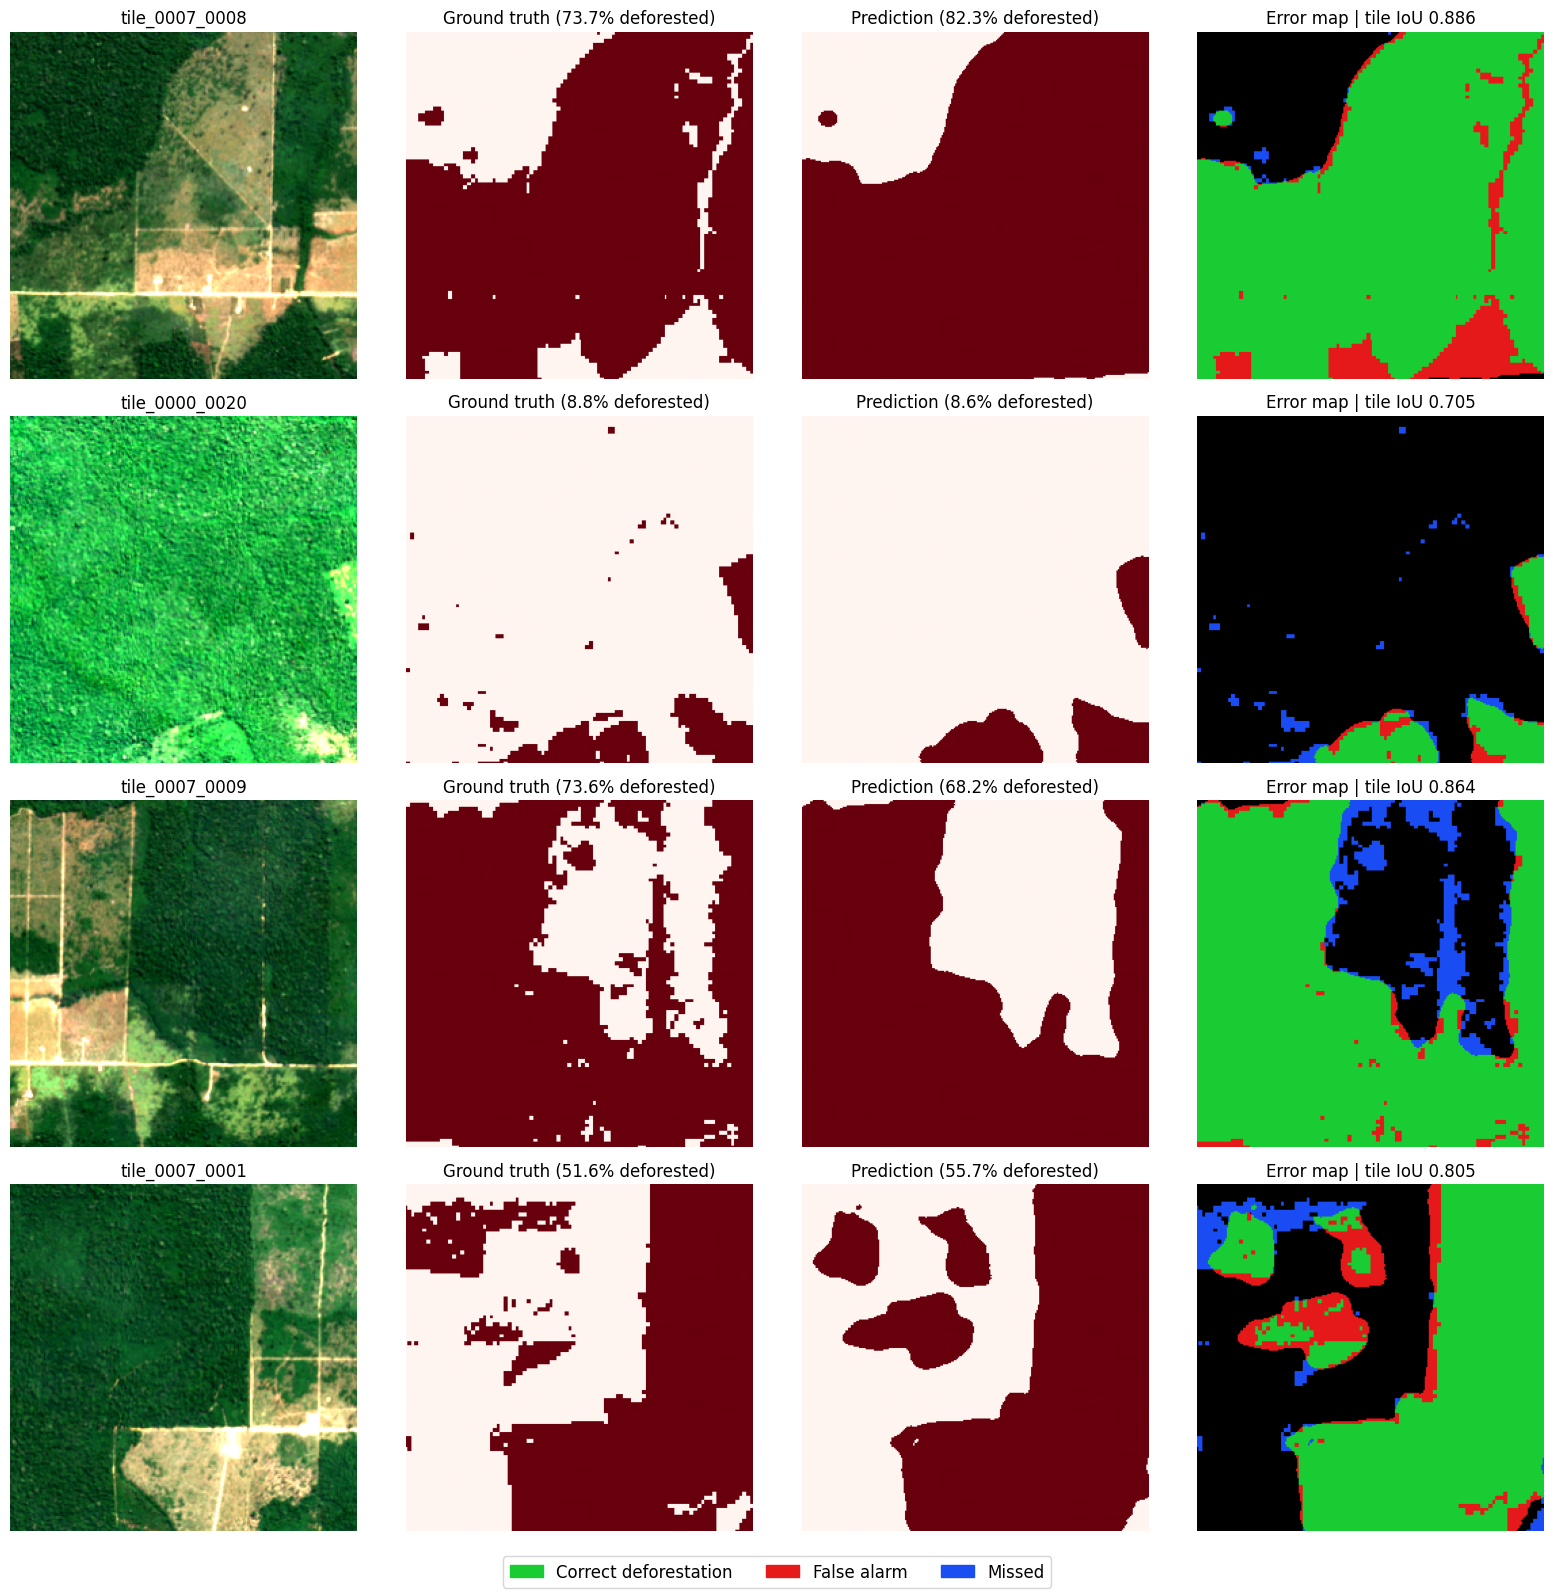

In [47]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

THRESHOLD = best_thr      
USE_TTA = True
N_TILES = 4
SEED = 7

model.load_state_dict(torch.load(BEST_PATH_V2, map_location=DEVICE))
model.to(DEVICE).eval()


def to_display_rgb(img_tensor):
    """Undo standardization, then stretch to 0-1 for display."""
    img = img_tensor.cpu().numpy().transpose(1, 2, 0)
    img = img * test_dataset.std + test_dataset.mean
    lo, hi = np.percentile(img, 2), np.percentile(img, 98)
    return np.clip((img - lo) / (hi - lo + 1e-8), 0, 1)


# Pick tiles that actually contain some deforestation, spread across the test set
rng = np.random.default_rng(SEED)
candidates = []
for i in range(len(test_dataset)):
    _, m = test_dataset[i]
    frac = m.mean().item()
    if 0.05 < frac < 0.9:
        candidates.append(i)
chosen = rng.choice(candidates, size=min(N_TILES, len(candidates)), replace=False)

fig, axes = plt.subplots(len(chosen), 4, figsize=(16, 4 * len(chosen)))
if len(chosen) == 1:
    axes = axes[None, :]

for row, idx in enumerate(chosen):
    img, mask = test_dataset[idx]
    with torch.no_grad():
        prob = predict_probs(img.unsqueeze(0).to(DEVICE), tta=USE_TTA)[0, 0].cpu().numpy()
    pred = (prob > THRESHOLD).astype(np.uint8)
    gt = mask[0].numpy().astype(np.uint8)

    tp = ((pred == 1) & (gt == 1))
    fp = ((pred == 1) & (gt == 0))
    fn = ((pred == 0) & (gt == 1))
    iou = tp.sum() / (tp.sum() + fp.sum() + fn.sum() + 1e-8)

    # error map: green = correct deforestation, red = false alarm, blue = missed
    err = np.zeros((*gt.shape, 3), dtype=np.float32)
    err[tp] = [0.1, 0.8, 0.2]
    err[fp] = [0.9, 0.1, 0.1]
    err[fn] = [0.1, 0.3, 0.95]

    axes[row, 0].imshow(to_display_rgb(img))
    axes[row, 0].set_title(f"{test_dataset.tile_ids[idx]}")
    axes[row, 1].imshow(gt, cmap="Reds", vmin=0, vmax=1)
    axes[row, 1].set_title(f"Ground truth ({gt.mean()*100:.1f}% deforested)")
    axes[row, 2].imshow(pred, cmap="Reds", vmin=0, vmax=1)
    axes[row, 2].set_title(f"Prediction ({pred.mean()*100:.1f}% deforested)")
    axes[row, 3].imshow(err)
    axes[row, 3].set_title(f"Error map | tile IoU {iou:.3f}")
    for ax in axes[row]:
        ax.axis("off")

legend = [Patch(color=(0.1, 0.8, 0.2), label="Correct deforestation"),
          Patch(color=(0.9, 0.1, 0.1), label="False alarm"),
          Patch(color=(0.1, 0.3, 0.95), label="Missed")]
fig.legend(handles=legend, loc="lower center", ncol=3, fontsize=12)
plt.tight_layout(rect=[0, 0.03, 1, 1])

save_path = os.path.join(OUT_DIR, "predictions_4_tiles.png")
plt.savefig(save_path, dpi=150, bbox_inches="tight")
print("Saved:", save_path)
plt.show()

In [49]:
!pip install -q openvino nncf onnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.1/59.1 MB 28.1 MB/s eta 0:00:0000:01:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.3/797.3 kB 30.1 MB/s eta 0:00:00


In [50]:
import os, time
import numpy as np
import pandas as pd
import torch
import openvino as ov
import nncf
from torch.utils.data import DataLoader
 
model.load_state_dict(torch.load(BEST_PATH_V2, map_location="cpu"))
model.eval().to("cpu")
 
ONNX_PATH = os.path.join(OUT_DIR, "unetpp_resnet34.onnx")
IR_FP32 = os.path.join(OUT_DIR, "ov_fp32", "model.xml")
IR_FP16 = os.path.join(OUT_DIR, "ov_fp16", "model.xml")
IR_INT8 = os.path.join(OUT_DIR, "ov_int8", "model.xml")
for p in (IR_FP32, IR_FP16, IR_INT8):
    os.makedirs(os.path.dirname(p), exist_ok=True)
 
torch.onnx.export(
    model, torch.randn(1, 3, 256, 256), ONNX_PATH,
    opset_version=17, dynamo=False,
    input_names=["input"], output_names=["logits"],
)
print("ONNX saved:", ONNX_PATH)

/tmp/ipykernel_48/764305636.py:19: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX saved: /kaggle/working/unetpp_resnet34.onnx


In [51]:
core = ov.Core()
print("Available devices:", core.available_devices)
 
ov_model = ov.convert_model(ONNX_PATH)
ov.save_model(ov_model, IR_FP32, compress_to_fp16=False)
ov.save_model(ov_model, IR_FP16, compress_to_fp16=True)
 
x, _ = test_dataset[0]
x = x.unsqueeze(0)
with torch.no_grad():
    ref = model(x).numpy()
 
compiled = core.compile_model(IR_FP32, "CPU")
out = compiled(x.numpy())[compiled.output(0)]
print("Max abs difference PyTorch vs OpenVINO FP32:", float(np.abs(ref - out).max()))

Available devices: ['CPU', 'GPU.0', 'GPU.1']
Max abs difference PyTorch vs OpenVINO FP32: 5.435943603515625e-05


In [52]:
calib_loader = DataLoader(train_dataset, batch_size=1, shuffle=True)
calib_data = nncf.Dataset(calib_loader, lambda batch: batch[0].numpy())
 
fp32_model = core.read_model(IR_FP32)
int8_model = nncf.quantize(fp32_model, calib_data, subset_size=300)
ov.save_model(int8_model, IR_INT8)
print("INT8 model saved:", IR_INT8)

Output()

Output()

INT8 model saved: /kaggle/working/ov_int8/model.xml


In [53]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))
 
 
def ov_metrics(ir_path, dataset, thr, device="CPU", tta=False):
    comp = core.compile_model(ir_path, device)
    out_node = comp.output(0)
    tp = fp = fn = 0.0
    for i in range(len(dataset)):
        xi, yi = dataset[i]
        xi = xi.unsqueeze(0).numpy()
        p = sigmoid(comp(xi)[out_node])
        if tta:
            p = p + np.flip(sigmoid(comp(np.flip(xi, -1).copy())[out_node]), -1)
            p = p + np.flip(sigmoid(comp(np.flip(xi, -2).copy())[out_node]), -2)
            p = p + np.flip(sigmoid(comp(np.flip(xi, (-1, -2)).copy())[out_node]), (-1, -2))
            p = p / 4
        pred = (p[0, 0] > thr).astype(np.float32)
        gt = yi[0].numpy()
        tp += (pred * gt).sum()
        fp += (pred * (1 - gt)).sum()
        fn += ((1 - pred) * gt).sum()
    iou = tp / (tp + fp + fn + 1e-8)
    prec = tp / (tp + fp + 1e-8)
    rec = tp / (tp + fn + 1e-8)
    f1 = 2 * prec * rec / (prec + rec + 1e-8)
    return {"iou": float(iou), "f1": float(f1)}
 
 
acc = {}
for name, path in [("FP32", IR_FP32), ("FP16", IR_FP16), ("INT8", IR_INT8)]:
    acc[name] = ov_metrics(path, test_dataset, best_thr)
    print(name, {k: round(v, 4) for k, v in acc[name].items()})
print("INT8 + TTA:", {k: round(v, 4) for k, v in ov_metrics(IR_INT8, test_dataset, best_thr, tta=True).items()})

FP32 {'iou': 0.7851, 'f1': 0.8796}
FP16 {'iou': 0.7851, 'f1': 0.8796}
INT8 {'iou': 0.7776, 'f1': 0.8749}
INT8 + TTA: {'iou': 0.8035, 'f1': 0.891}


In [54]:
def bench_latency(comp, n=100, warmup=10):
    inp = np.random.randn(1, 3, 256, 256).astype(np.float32)
    for _ in range(warmup):
        comp(inp)
    times = []
    for _ in range(n):
        s = time.perf_counter()
        comp(inp)
        times.append((time.perf_counter() - s) * 1000)
    return float(np.mean(times)), float(np.percentile(times, 95))
 
 
def bench_throughput(ir_path, device, n=200):
    comp = core.compile_model(ir_path, device, {"PERFORMANCE_HINT": "THROUGHPUT"})
    queue = ov.AsyncInferQueue(comp)
    inp = np.random.randn(1, 3, 256, 256).astype(np.float32)
    for _ in range(10):
        queue.start_async({0: inp})
    queue.wait_all()
    s = time.perf_counter()
    for _ in range(n):
        queue.start_async({0: inp})
    queue.wait_all()
    return n / (time.perf_counter() - s)
 
 
rows = []
 
# PyTorch CPU baseline
model.eval().to("cpu")
inp_t = torch.randn(1, 3, 256, 256)
with torch.no_grad():
    for _ in range(10):
        model(inp_t)
    t = []
    for _ in range(100):
        s = time.perf_counter()
        model(inp_t)
        t.append((time.perf_counter() - s) * 1000)
rows.append({"Framework": "PyTorch", "Device": "CPU", "Precision": "FP32",
             "Latency ms (mean)": np.mean(t), "Latency ms (p95)": np.percentile(t, 95),
             "Throughput (tiles/s)": 1000 / np.mean(t),
             "Test IoU": None})
 
for device in core.available_devices:
    for prec, path in [("FP32", IR_FP32), ("FP16", IR_FP16), ("INT8", IR_INT8)]:
        try:
            comp = core.compile_model(path, device, {"PERFORMANCE_HINT": "LATENCY"})
            lat_mean, lat_p95 = bench_latency(comp)
            thr_fps = bench_throughput(path, device)
            rows.append({"Framework": "OpenVINO", "Device": device, "Precision": prec,
                         "Latency ms (mean)": lat_mean, "Latency ms (p95)": lat_p95,
                         "Throughput (tiles/s)": thr_fps,
                         "Test IoU": acc[prec]["iou"] if device == "CPU" else None})
        except Exception as e:
            print(f"Skipped {device} {prec}: {str(e)[:100]}")
 
results = pd.DataFrame(rows).round(3)
base = results.loc[0, "Latency ms (mean)"]
results["Speedup vs PyTorch"] = (base / results["Latency ms (mean)"]).round(2)
print(results.to_string(index=False))
results.to_csv(os.path.join(OUT_DIR, "benchmark_results.csv"), index=False)
 
print("\nCPU in use:", core.get_property("CPU", "FULL_DEVICE_NAME"))

105 warnings generated.
105 warnings generated.
105 warnings generated.
105 warnings generated.
107 warnings generated.
105 warnings generated.
105 warnings generated.
105 warnings generated.
105 warnings generated.
105 warnings generated.
1 warning generated.
2 warnings generated.
1 warning generated.
106 warnings generated.
106 warnings generated.
105 warnings generated.
107 warnings generated.
1 warning generated.
1 warning generated.
108 warnings generated.
106 warnings generated.
1 warning generated.
106 warnings generated.
105 warnings generated.
1 warning generated.
106 warnings generated.
105 warnings generated.
2 warnings generated.
105 warnings generated.
107 warnings generated.
105 warnings generated.
1 warning generated.
1 warning generated.
2 warnings generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
2 warnings generated.
1 warning generated.
2 warnings generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 

Framework Device Precision  Latency ms (mean)  Latency ms (p95)  Throughput (tiles/s)  Test IoU  Speedup vs PyTorch
  PyTorch    CPU      FP32            254.555           265.360                 3.928       NaN                1.00
 OpenVINO    CPU      FP32            157.238           165.678                 6.700     0.785                1.62
 OpenVINO    CPU      FP16            160.531           169.598                 6.695     0.785                1.59
 OpenVINO    CPU      INT8            105.013           108.833                 9.857     0.778                2.42
 OpenVINO  GPU.0      FP32            220.431           222.590                 4.748       NaN                1.15
 OpenVINO  GPU.0      FP16            210.534           211.943                 4.738       NaN                1.21
 OpenVINO  GPU.0      INT8            158.629           160.248                 6.345       NaN                1.60
 OpenVINO  GPU.1      FP32            187.056           188.706         